# Natural Language Processing with Disaster Tweets

This is my first Kaggle competition for NLP, the aim here is to learn and become more comfortable with: 
- Text cleaning and preprocessing (handling hashtags, URLs, etc.).
- Classic feature extraction: Bag-of-Words, TF-IDF.
- Building simple baseline models: Logistic Regression, Naive Bayes.
- Introduction to deep learning: LSTMs, GRUs, and eventually fine-tuning a basic Transformer like DistilBERT.


**The Task:** Predict whether a given tweet is about a real disaster or not. It's a classic binary text classification problem.


Pathways for improvement:
https://www.kaggle.com/code/gunesevitan/nlp-with-disaster-tweets-eda-cleaning-and-bert#7.-Model

Getting started:
https://www.kaggle.com/code/alexdavidson1995/kerasnlp-starter-notebook-disaster-tweets/edit



### 1. Introduction and Data Loading 📝

First, the notebook sets a clear goal: to classify tweets as being about a real disaster or not. It then loads the training and testing datasets using pandas and performs a quick initial inspection to understand their structure, including the columns (id, keyword, location, text, target), size, and memory usage.

### 2. Exploratory Data Analysis (EDA) 📊

This is a deep dive into the data to uncover patterns that could help with modeling. The main findings were:

Word Frequency: Disaster-related tweets frequently use words like "fire," "suicide," "bomber," and "hiroshima." Non-disaster tweets feature more casual words like "lol," "love," and "video." Bigrams (two-word phrases) like "suicide bomber" and "oil spill" were strong indicators of a disaster.

Tweet Features: URLs are significantly more common in disaster tweets, likely because they link to news articles. Mentions and hashtags, however, are more evenly distributed.

Metadata: The keyword and location columns were analyzed. Certain keywords like "derailment" and "wreckage" were highly correlated with real disasters. Location data was found to be messy but showed some patterns, with places like the "USA" and "Nigeria" appearing frequently.

Class Balance: The dataset is fairly balanced, with about 43% of tweets labeled as disasters and 57% as non-disasters.

### 3. Data Preprocessing and Splitting 🧼

This stage prepares the text data for the models.

Universal Cleaning: A cleaning function was created to standardize the text for all models. This involved:

Lowercasing the text.

Removing HTML entities (like &amp;).

Replacing URLs and user mentions with special tokens like <URL> and <USER> to preserve their signal without adding noise.

Removing the # symbol but keeping the hashtag text.

Train-Validation Split: The cleaned training data was split into a training set (80%) and a validation set (20%). A stratified split was used to ensure that both sets had the same percentage of disaster and non-disaster tweets, which is crucial for reliable evaluation.

### 4. Model Building and Training ⚙️

Four different models were developed, ranging from simple baselines to more complex deep learning architectures.

Logistic Regression: A classic machine learning model combined with a TfidfVectorizer. This approach converts text into numerical features based on word importance (TF-IDF) and then learns a simple linear boundary to separate the classes.

Naive Bayes: Another classic model, specifically MultinomialNB, which is well-suited for text classification. It was also paired with a TfidfVectorizer to work with word frequencies.

LSTM (Long Short-Term Memory): A deep learning model built with TensorFlow/Keras. It uses an Embedding layer to learn semantic relationships between words and a Bidirectional LSTM layer to understand the context of words in a sequence.

DistilBERT: A modern, transformer-based model using the keras_nlp library. It was fine-tuned in two stages: first by training only the final classification layer (a "linear probe"), and then by unfreezing the entire model for a short period with a low learning rate.

### 5. Evaluation and Submission 🏆

Finally, the models were compared to select the best one.

Performance Metrics: The models were evaluated on the validation set using accuracy, F1-score, and AUC. The Logistic Regression model achieved the highest F1-score (0.755), making it the best performer among the fully trained models.

Confusion Matrices: Visualizations were created to show the performance of the top three models, highlighting their strengths and weaknesses in distinguishing between the two classes.

Submission: The best model, Logistic Regression, was used to make predictions on the test set. These predictions were then saved to submission.csv in the format required by the Kaggle competition.


In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import tensorflow as tf
import keras_core as keras
import keras_nlp
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("KerasNLP version:", keras_nlp.__version__)


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

2025-10-16 12:23:10.155169: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1760617390.369527      37 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1760617390.433338      37 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Using TensorFlow backend
TensorFlow version: 2.18.0
KerasNLP version: 0.18.1
/kaggle/input/nlp-getting-started/sample_submission.csv
/kaggle/input/nlp-getting-started/train.csv
/kaggle/input/nlp-getting-started/test.csv
/kaggle/input/distil_bert/keras/distil_bert_base_en_uncased/2/config.json
/kaggle/input/distil_bert/keras/distil_bert_base_en_uncased/2/tokenizer.json
/kaggle/input/distil_bert/keras/distil_bert_base_en_uncased/2/metadata.json
/kaggle/input/distil_bert/keras/distil_bert_base_en_uncased/2/model.weights.h5
/kaggle/input/distil_bert/keras/distil_bert_base_en_uncased/2/assets/tokenizer/vocabulary.txt


# Load the Disaster Tweets
Let's have a look at the train and test dataset.

They contain:

id
keyword: A keyword from that tweet (although this may be blank!)
location: The location the tweet was sent from (may also be blank)
text: The text of a tweet
target: 1 if the tweet is a real disaster or 0 if not

In [5]:
df_train = pd.read_csv("/kaggle/input/nlp-getting-started/train.csv")
df_test = pd.read_csv("/kaggle/input/nlp-getting-started/test.csv")

print('Training Set Shape = {}'.format(df_train.shape))
print('Training Set Memory Usage = {:.2f} MB'.format(df_train.memory_usage().sum() / 1024**2))
print('Test Set Shape = {}'.format(df_test.shape))
print('Test Set Memory Usage = {:.2f} MB'.format(df_test.memory_usage().sum() / 1024**2))

Training Set Shape = (7613, 5)
Training Set Memory Usage = 0.29 MB
Test Set Shape = (3263, 4)
Test Set Memory Usage = 0.10 MB


In [6]:
df_train.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [16]:
df_test.head()

,id,keyword,location,text
0,0,NaN,NaN,Just happened a terrible car crash
1,2,NaN,NaN,"Heard about #earthquake is different cities, s..."
2,3,NaN,NaN,"there is a forest fire at spot pond, geese are..."
3,9,NaN,NaN,Apocalypse lighting. #Spokane #wildfires
4,11,NaN,NaN,Typhoon Soudelor kills 28 in China and Taiwan


# Explore the dataset

Do a preliminary exploration of the data to get a sense of it:

**1. Analyze Word and Phrase Frequency**

Understanding the most common words and phrases in each class (disaster vs. non-disaster) is one of the most revealing steps. This helps you see which terms are strong signals for a real disaster.

Top Words (Unigrams): Look for words that are highly frequent in the "disaster" class but not in the "non-disaster" class.

Top Phrases (Bigrams/Trigrams): Looking at pairs or triplets of words gives you more context. For example, "oil spill" or "suicide bomber" are more informative than the individual words.


**2. Investigate Tweet-Specific Features**

Tweets have unique metadata that you can easily count and analyze.

Hashtags (#) and Mentions (@): Do disaster tweets use hashtags differently? Are they more likely to mention official sources like news outlets or emergency services?

URLs (http): Are real disaster tweets more likely to contain links, perhaps to news articles?

What you'll likely find: You might discover that real disaster tweets often contain URLs, while non-disaster tweets (especially jokes or metaphors) might use more hashtags.


**3. Explore the keyword and location Columns**

These columns provide extra context.

Top Keywords: Which keywords are most associated with real disaster tweets? You can create a bar chart showing the percentage of real vs. fake disasters for each common keyword.

Top Locations: The location data is messy, but you can still find the most common locations and see if any patterns emerge.

In [7]:
df_train["length"] = df_train["text"].apply(lambda x : len(x))
df_test["length"] = df_test["text"].apply(lambda x : len(x))

print("Train Length Stat")
print(df_train["length"].describe())
print()

print("Test Length Stat")
print(df_test["length"].describe())

Train Length Stat
count    7613.000000
mean      101.037436
std        33.781325
min         7.000000
25%        78.000000
50%       107.000000
75%       133.000000
max       157.000000
Name: length, dtype: float64

Test Length Stat
count    3263.000000
mean      102.108183
std        33.972158
min         5.000000
25%        78.000000
50%       109.000000
75%       134.000000
max       151.000000
Name: length, dtype: float64


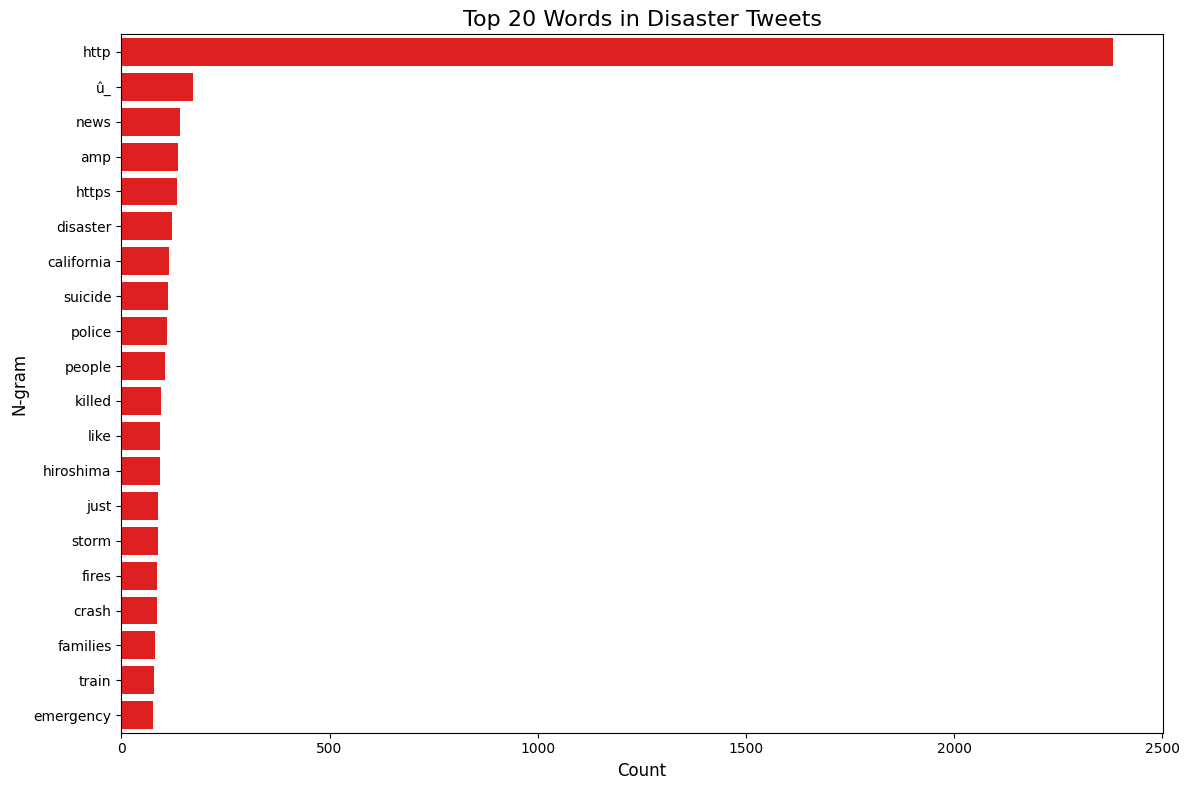

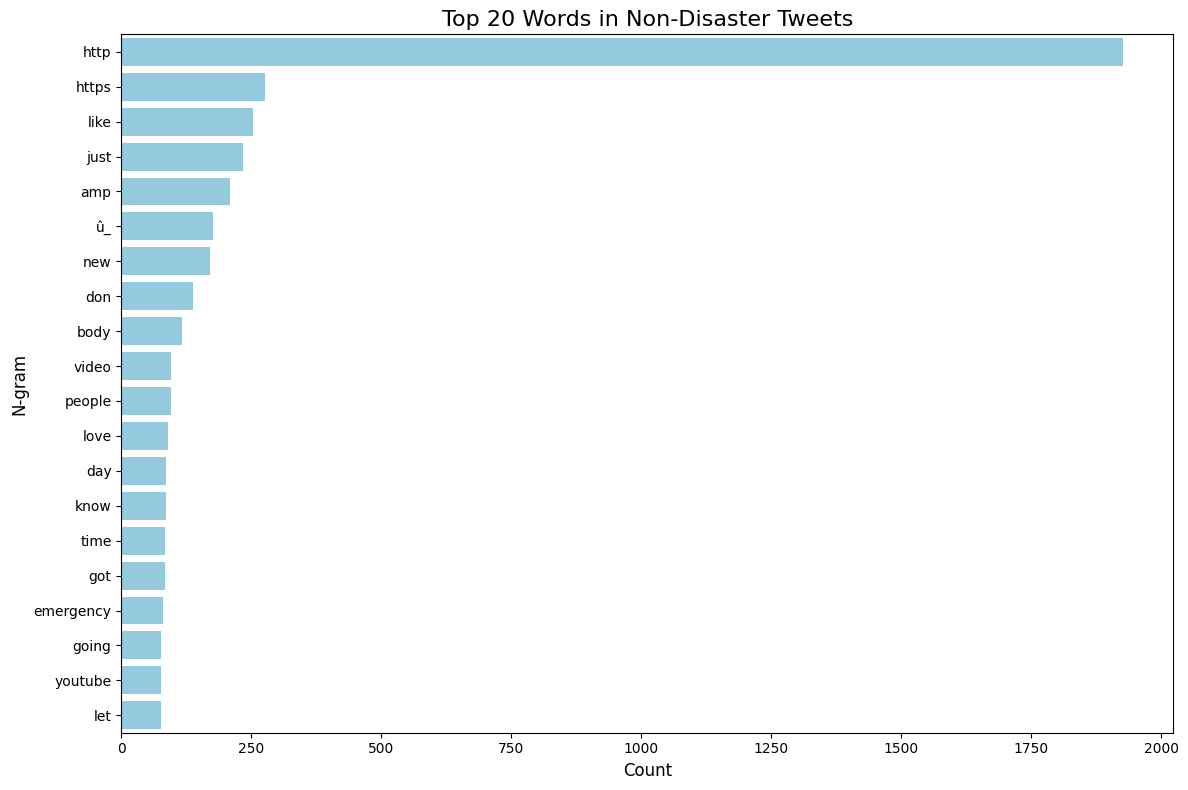

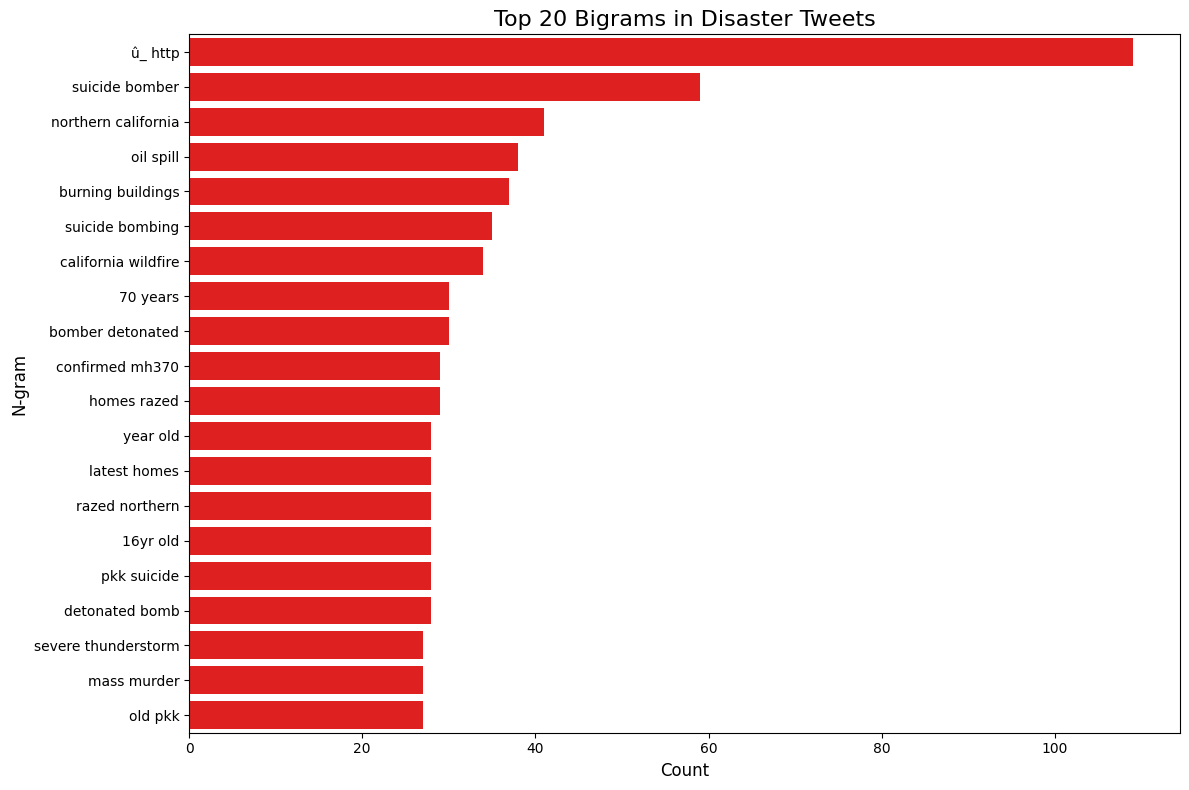

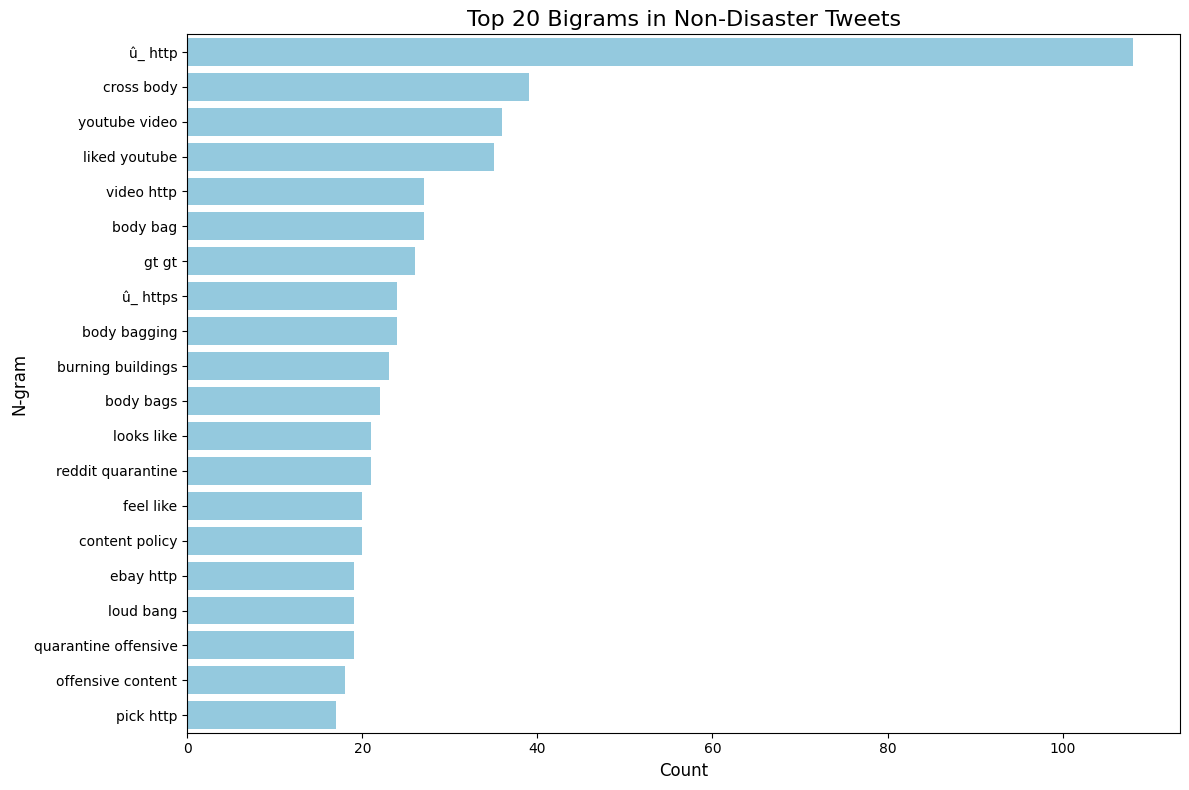

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated a

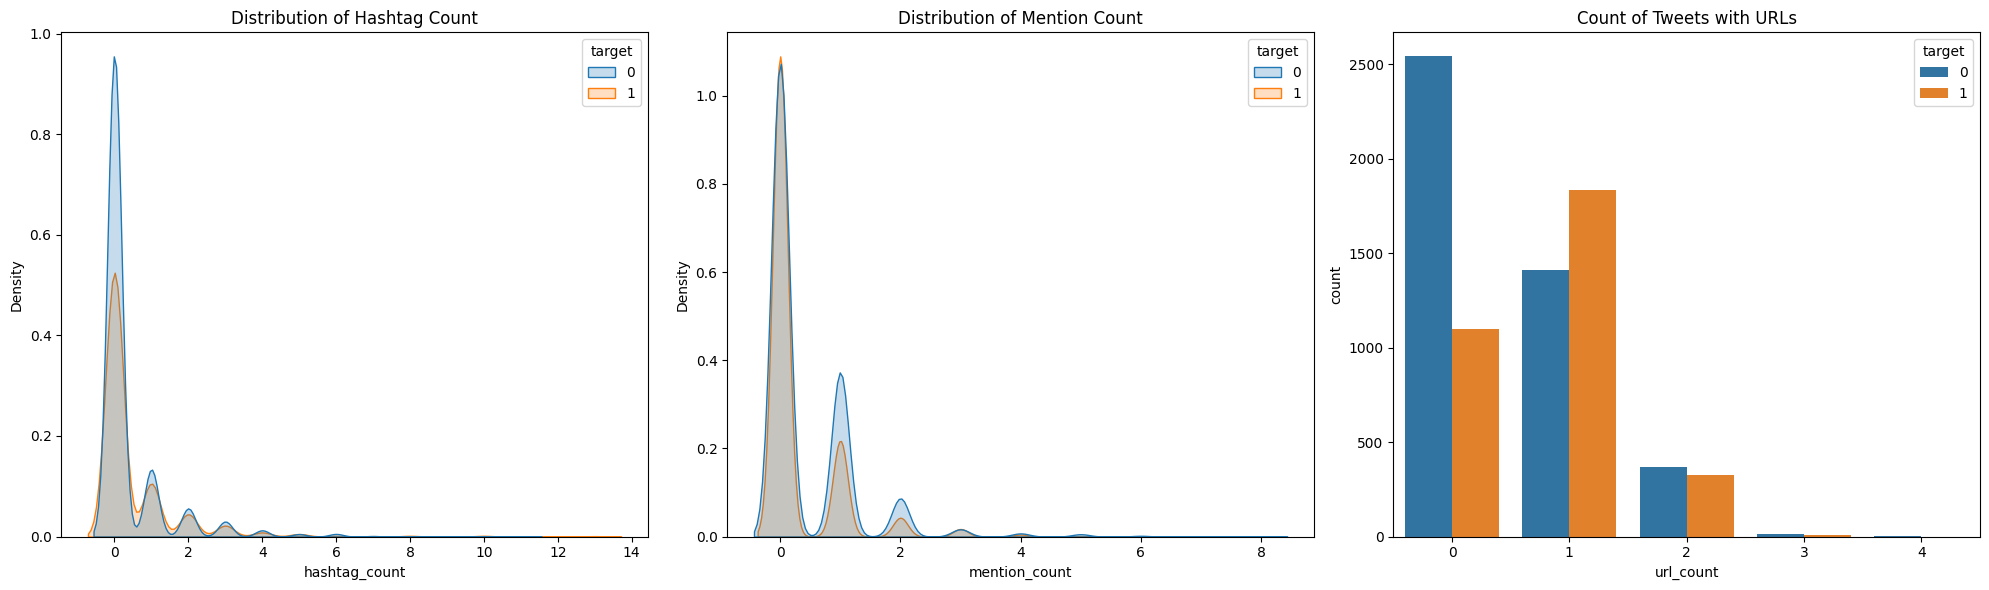

/tmp/ipykernel_37/883900621.py:64: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_train['keyword'].fillna('None', inplace=True)


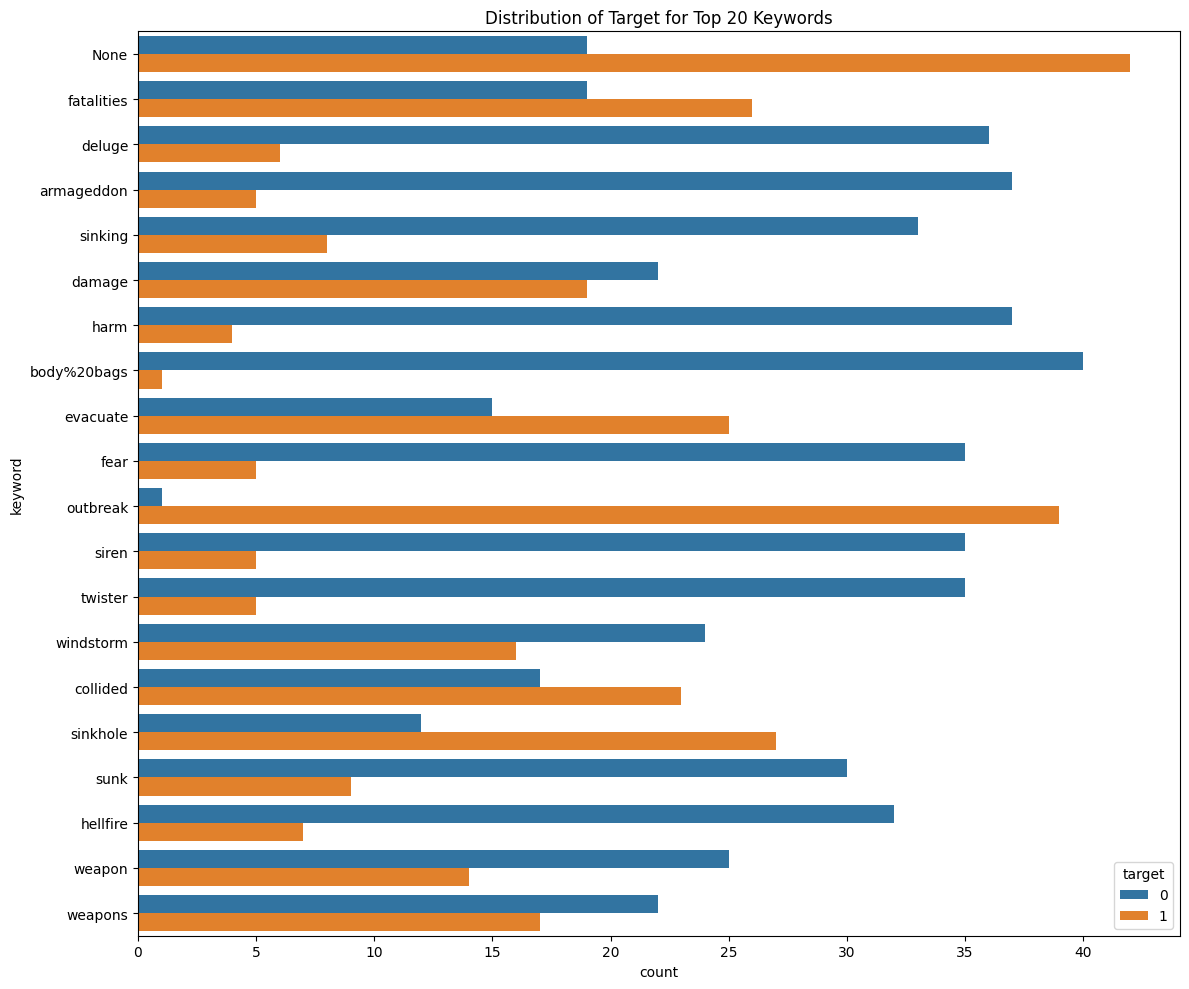

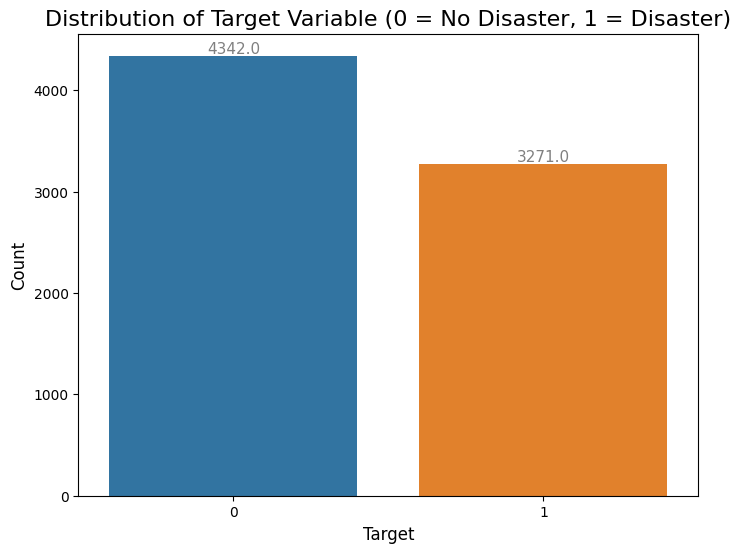

/tmp/ipykernel_37/883900621.py:104: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_train['location'].fillna('Unknown', inplace=True)
/tmp/ipykernel_37/883900621.py:105: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', tr

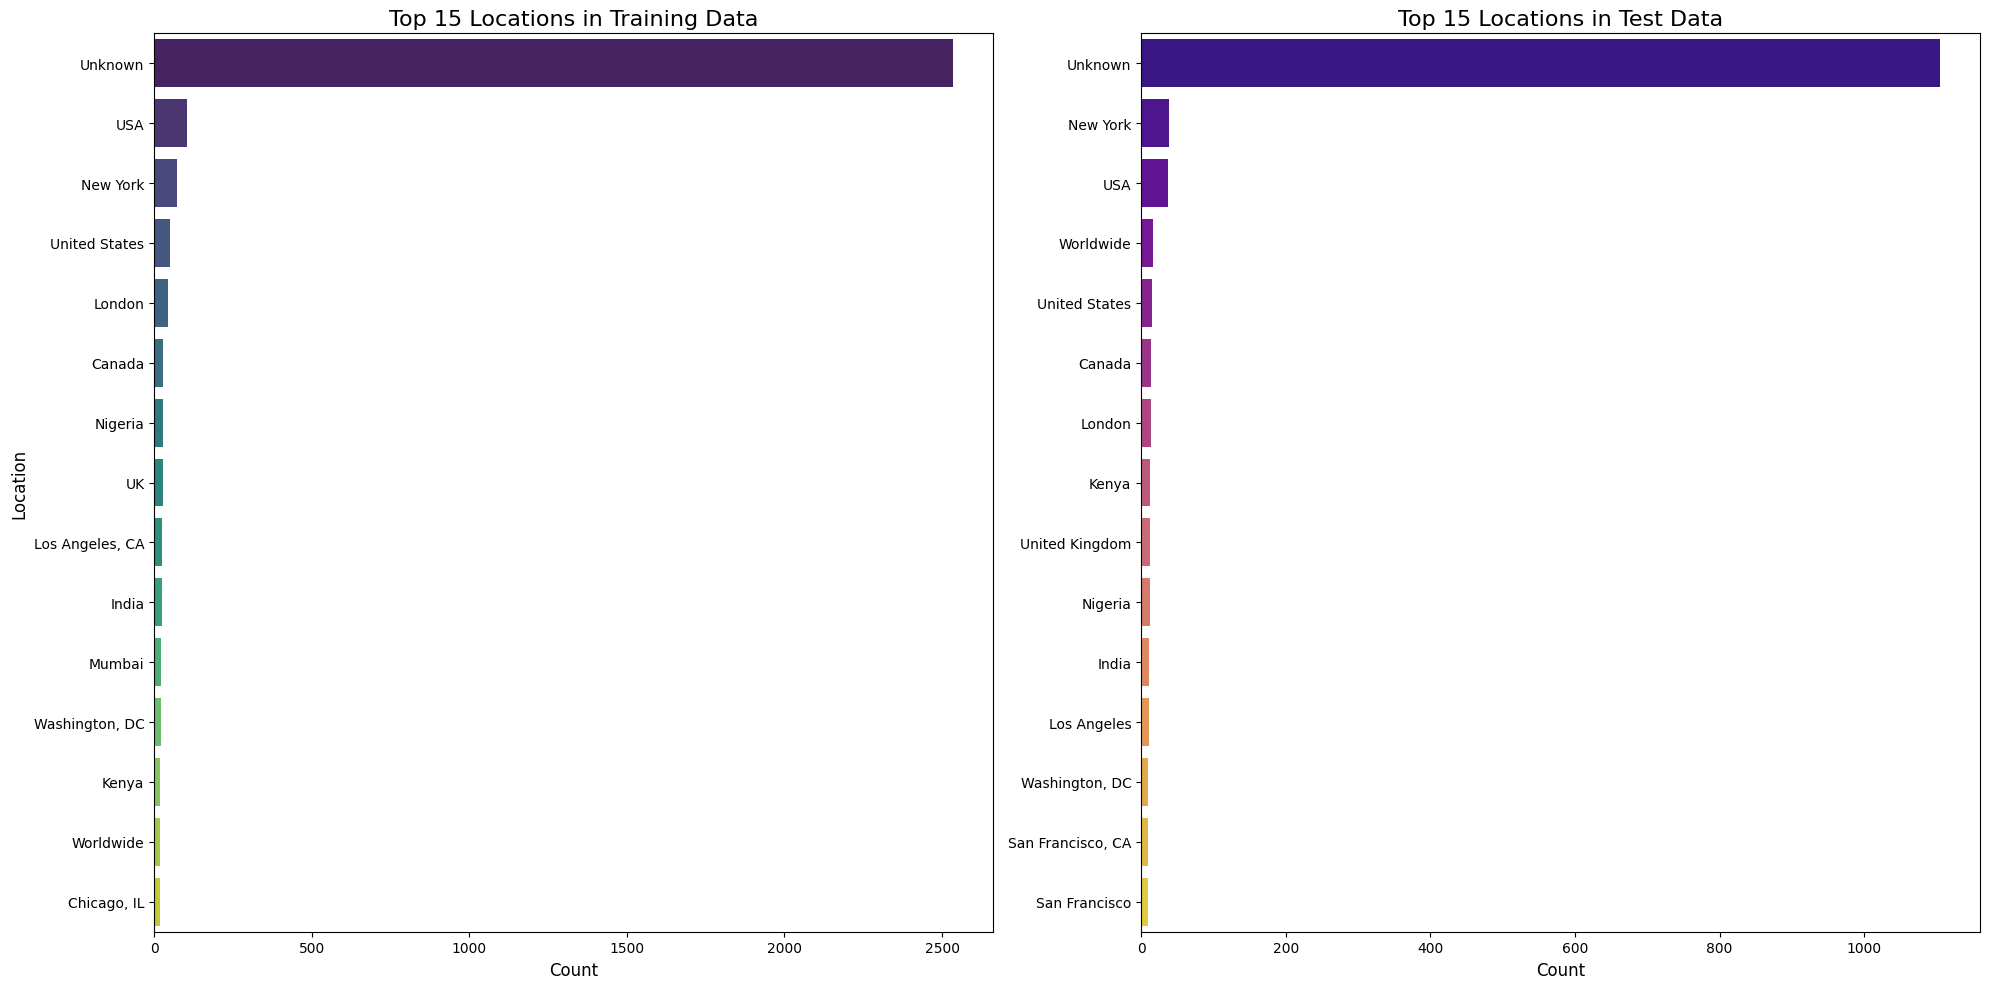

In [8]:
import re
from sklearn.feature_extraction.text import CountVectorizer

# --- 1. Word and Phrase Frequency Analysis ---


# Separate the tweets by class
disaster_tweets = df_train[df_train['target'] == 1]['text']
non_disaster_tweets = df_train[df_train['target'] == 0]['text']


def get_top_n_words(corpus, n=20, ngram_range=(1,1)):
    """
    Get the top N words or n-grams from a corpus of text.
    """
    vec = CountVectorizer(stop_words='english', ngram_range=ngram_range).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key = lambda x: x[1], reverse=True)
    return words_freq[:n]


def plot_top_ngrams(ngrams, title, color):
    """Function to plot top n-grams"""
    df = pd.DataFrame(ngrams, columns=['ngram', 'count'])
    plt.figure(figsize=(12, 8))
    sns.barplot(x='count', y='ngram', data=df, color=color)
    plt.title(title, fontsize=16)
    plt.xlabel('Count', fontsize=12)
    plt.ylabel('N-gram', fontsize=12)
    plt.tight_layout()
    plt.show()


# Plot top words and bigrams for each class
plot_top_ngrams(get_top_n_words(disaster_tweets, ngram_range=(1,1)), 'Top 20 Words in Disaster Tweets', 'red')
plot_top_ngrams(get_top_n_words(non_disaster_tweets, ngram_range=(1,1)), 'Top 20 Words in Non-Disaster Tweets', 'skyblue')
plot_top_ngrams(get_top_n_words(disaster_tweets, ngram_range=(2,2)), 'Top 20 Bigrams in Disaster Tweets', 'red')
plot_top_ngrams(get_top_n_words(non_disaster_tweets, ngram_range=(2,2)), 'Top 20 Bigrams in Non-Disaster Tweets', 'skyblue')


# --- 2. Tweet-Specific Feature Analysis ---

df_train['hashtag_count'] = df_train['text'].apply(lambda x: len(re.findall(r'#', x)))
df_train['mention_count'] = df_train['text'].apply(lambda x: len(re.findall(r'@', x)))
df_train['url_count'] = df_train['text'].apply(lambda x: len(re.findall(r'http', x)))

# Plot distribution of these features
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.kdeplot(data=df_train, x='hashtag_count', hue='target', fill=True, ax=axes[0])
axes[0].set_title('Distribution of Hashtag Count')
sns.kdeplot(data=df_train, x='mention_count', hue='target', fill=True, ax=axes[1])
axes[1].set_title('Distribution of Mention Count')
sns.countplot(data=df_train, x='url_count', hue='target', ax=axes[2])
axes[2].set_title('Count of Tweets with URLs')
plt.tight_layout()
plt.show()


# --- 3. Keyword Analysis ---

# Fill NaN values for plotting
df_train['keyword'].fillna('None', inplace=True)
top_keywords = df_train['keyword'].value_counts().head(20).index

plt.figure(figsize=(12, 10))
sns.countplot(y='keyword', hue='target', data=df_train[df_train['keyword'].isin(top_keywords)], order=top_keywords)
plt.title('Distribution of Target for Top 20 Keywords')
plt.tight_layout()
plt.show()



import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Assume df_train and df_test are already loaded
# Example:
# df_train = pd.read_csv('train.csv')
# df_test = pd.read_csv('test.csv')


# --- 1. Distribution of Target Variable in Training Set ---

plt.figure(figsize=(8, 6))
sns.countplot(x='target', data=df_train)
plt.title('Distribution of Target Variable (0 = No Disaster, 1 = Disaster)', fontsize=16)
plt.xlabel('Target', fontsize=12)
plt.ylabel('Count', fontsize=12)
# Adding labels to the bars
ax = plt.gca()
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=11, color='gray', xytext=(0, 5),
                textcoords='offset points')
plt.show()


# --- 2. Distribution of Top Locations in Train vs. Test Sets ---

# Fill NaN values to make them countable
df_train['location'].fillna('Unknown', inplace=True)
df_test['location'].fillna('Unknown', inplace=True)

# Get the top 15 most common locations from each dataframe
top_locations_train = df_train['location'].value_counts().head(15)
top_locations_test = df_test['location'].value_counts().head(15)

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Plot for training data
sns.barplot(y=top_locations_train.index, x=top_locations_train.values, ax=axes[0], palette='viridis')
axes[0].set_title('Top 15 Locations in Training Data', fontsize=16)
axes[0].set_xlabel('Count', fontsize=12)
axes[0].set_ylabel('Location', fontsize=12)

# Plot for test data
sns.barplot(y=top_locations_test.index, x=top_locations_test.values, ax=axes[1], palette='plasma')
axes[1].set_title('Top 15 Locations in Test Data', fontsize=16)
axes[1].set_xlabel('Count', fontsize=12)
axes[1].set_ylabel('') # Hide y-label for cleaner look

plt.tight_layout()
plt.show()


# Preprocess the data

The aim here is to preprocess the data ready to train the model on. However the preprocessing is highly dependent on the type of model you want to train. The aim is to train **logistic regression, Naive Bayes, LSTM and fine-tuned BERT** on this data.

## "Universal" pre-processing relevant to all models

Visualisation of universal pre-processing of data: https://www.kaggle.com/code/alexdavidson1995/nlp-disaster-tweets-preprocessing-and-tf-idf


These are “universal” steps that you should do regardless of the classifier:

| Step | Why it matters |
|------|----------------|
| Drop duplicates and handle NaN | Prevents leakage and meaningless inputs. |
| Lowercasing | Keeps vocab consistent *(except for cased BERT).* |
| Basic normalization (remove weird whitespace, fix HTML entities) | Makes data cleaner for tokenization. |
| Preserve semantic tokens | Replace URLs and mentions with placeholders (`<URL>`, `<USER>`). Don’t delete them — they carry signal. |
| Stratified train/val/test split | Keeps class distribution consistent across sets. |
| Seed setting for reproducibility | Ensures repeatable results. |

In [11]:
### Universal preprocessing

# --- Universal imports & hygiene ---
import os, re, html, random
from sklearn.model_selection import train_test_split


# --- 1️⃣ Reproducibility setup ---
# Ensures all random operations (like shuffling, weight initialization, and hashing)
# behave the same every time you run the code — important for consistent, repeatable experiments.
# needed to make sure that the train test split takes a random sample from positive and negative tweets

SEED = 42
random.seed(SEED)          # Sets Python's built-in random number generator
np.random.seed(SEED)       # Sets NumPy's random number generator
os.environ["PYTHONHASHSEED"] = str(SEED)  # Makes Python’s internal hashing deterministic - i.e. means that when re-running this model you can have the exat same weights and dataset



# --- 2️⃣ Compile regular expressions for common tweet patterns ---
# Pre-compile for speed and readability.
# - URL_RE: matches URLs like 'https://something.com' swaps the html in the text for <HTML> as the URL is often irrelevant to the NLP task
URL_RE = re.compile(r"https?://\S+|www\.\S+")

# - MENTION_RE: matches Twitter mentions like '@user' > replaces it with <USER> as the username is often irrelevant to the NLP task
MENTION_RE = re.compile(r"@\w+")


# - HASHTAG_RE: matches hashtags like '#fire' but captures just the word part - replaces it with <HASHTAG> as often its irrelevant
HASHTAG_RE = re.compile(r"#(\w+)")




# --- 3️⃣ Universal cleaning function for all models ---
# This function:
#  • Handles NaN or non-string inputs safely
#  • Decodes HTML entities (e.g. '&amp;' → '&')
#  • Replaces URLs and mentions with placeholders (<URL>, <USER>)
#  • Removes '#' while keeping the hashtag word itself
#  • Fixes common text artifacts like '&amp;' or excessive spaces
#  • Lowercases text for consistent tokenization (except for cased BERT)
def clean_universal(text: str) -> str:
    if not isinstance(text, str):
        return ""
    s = html.unescape(text)
    s = URL_RE.sub(" <URL> ", s)
    s = MENTION_RE.sub(" <USER> ", s)
    s = HASHTAG_RE.sub(r" \1 ", s)          # keep the hashtag word
    s = s.replace("&amp;", "and")
    s = re.sub(r"\s+", " ", s).strip()
    # Lowercase universally EXCEPT when using a *cased* transformer later.
    s = s.lower()
    return s

# Hygiene (before split)
df_train = df_train.drop_duplicates(subset=["text"]).copy()
df_train["text"] = df_train["text"].fillna("")
df_test["text"]  = df_test["text"].fillna("")

# Clean text
df_train["text_clean"] = df_train["text"].apply(clean_universal)
df_test["text_clean"]  = df_test["text"].apply(clean_universal)


# Stratified split (train/val)
X = df_train["text_clean"].values
y = df_train["target"].values
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y, shuffle=True
)

X_test = df_test["text_clean"].values

## Model-specific preprocessing

Below are the preprocessings needed for each type of model

| Model | Additional preprocessing | Notes |
|--------|---------------------------|-------|
| Logistic Regression (TF-IDF) | Lemmatization *(optional)*; remove stopwords *(optional)*; use `TfidfVectorizer` with word or char n-grams. | Works best with relatively clean text. Over-cleaning may hurt performance on short tweets. |
| Naive Bayes (Bag-of-Words / TF-IDF) | Same as Logistic Regression. | Naive Bayes benefits from presence/absence features, so binary counts or TF-IDF are fine. |
| LSTM (Word Embedding) | Tokenize and pad sequences; set `max_len` ~64–128; use vocabulary limited to frequent tokens. Avoid stemming. | Keep inflected forms; embedding captures semantics. |
| BERT (Transformer fine-tuning) | Use pretrained tokenizer (`bert-base-uncased`, `BERTweet`, etc.); do not lowercase if using a cased model; don’t remove stopwords or hashtags. | BERT’s tokenizer expects raw text with placeholders like `<URL>`, `<USER>`. |


Summary table:

| Step | Logistic Reg / NB | LSTM | BERT |
|------|--------------------|------|------|
| Drop NaN / duplicates | ✅ | ✅ | ✅ |
| Lowercase | ✅ | ✅ | ❌ *(unless using uncased model)* |
| Replace URLs / mentions | ✅ | ✅ | ✅ |
| Remove punctuation | ✅ *(optional)* | ❌ *(keep tokens for embeddings)* | ❌ *(let tokenizer handle it)* |
| Lemmatization / stemming | ✅ *(optional)* | ❌ | ❌ |
| Remove stopwords | ✅ *(optional)* | ❌ | ❌ |
| Tokenize & pad | ❌ | ✅ | ✅ *(via model tokenizer)* |
| TF-IDF / BoW | ✅ | ❌ | ❌ |
| Word embeddings | ❌ | ✅ | ✅ *(pretrained inside model)* |
| Sequence length truncation | ❌ | ✅ | ✅ |


### Evaluation — unify for comparison

After training each model:
Use the **same validation/test split.**
Compare **accuracy, F1-score (macro), and AUC**.
Optionally compare **inference time and parameter count.**

## Logistic Regression preprocessing

### 🧠 Understanding TF-IDF (Term Frequency–Inverse Document Frequency)

Visualisation of how TF-IDF works: https://www.kaggle.com/code/alexdavidson1995/nlp-disaster-tweets-preprocessing-and-tf-idf

TF-IDF is a method for turning **text into numerical features** so that a machine learning model (like Logistic Regression) can use it.

It balances two main ideas:

- **Term Frequency (TF):** How often a word appears in a document  
  → Common words in a document are given higher weight.
- **Inverse Document Frequency (IDF):** How unique a word is across the dataset  
  → Words that appear in many documents get lower weight.

**Goal:**  
Words that appear often in one document but rarely across others get **higher importance**, as they help distinguish between classes.

---

### 🧩 `TfidfVectorizer` Settings in the Code

**Example:**

`TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True, stop_words=None)`

| Parameter | Description | Why It’s Used |
|------------|--------------|---------------|
| **`ngram_range=(1, 2)`** | Includes unigrams (single words) and bigrams (two-word phrases) | Captures short phrases and context (e.g. “not good” ≠ “good”) |
| **`min_df=2`** | Ignores words appearing in fewer than 2 documents | Removes noise, typos, and extremely rare words |
| **`max_df=0.95`** | Ignores words appearing in more than 95% of documents | Filters out overly common, non-informative words |
| **`sublinear_tf=True`** | Applies logarithmic scaling to term frequency | Prevents long texts or repeated words from dominating |
| **`stop_words=None`** | Keeps all words (you could use `'english'` to remove stopwords) | Retains contextually important short words |

---

### ⚙️ What Happens During `fit()`

When you run `pipe_lr.fit(X_train, y_train)`:

1. **TF-IDF Stage**  
   - Learns the vocabulary (set of unique words/phrases that meet the filters)  
   - Calculates IDF values for each term  
   - Transforms text into a sparse matrix of TF-IDF scores  

2. **Logistic Regression Stage**  
   - Trains on the TF-IDF feature matrix  
   - Learns which features (words) are most predictive of each class  

---

### 🧾 Example Output of TF-IDF

Each document becomes a **vector** of weighted word features.

| Term | TF-IDF Weight |
|------|----------------|
| `fire` | 0.42 |
| `forest fire` | 0.37 |
| `smoke` | 0.21 |
| `and` | 0.00 (filtered out) |

---

### 💡 Why TF-IDF Works Well

- **Fast and interpretable**  
- Great for traditional NLP tasks (e.g., disaster tweet detection, sentiment analysis, spam filtering)  
- Works well with **linear models** like Logistic Regression or SVM  

---

### 🧭 Key Takeaway

> **TF-IDF transforms raw text into weighted numerical features, and Logistic Regression learns patterns from those weights.**  
> It ensures that words are weighted by how *informative* they are, not just how *frequent* they are.

---

### 🧮 Mathematical Intuition

For a term *t* in document *d*:

$$
\text{TF-IDF}(t, d) = (1 + \log(\text{TF}(t, d))) \times \log\left(\frac{N}{1 + \text{DF}(t)}\right)
$$

Where:  
- **TF(t, d):** Count of term *t* in document *d*  
- **DF(t):** Number of documents containing term *t*  
- **N:** Total number of documents  

This scaling rewards terms that are **frequent in a document** but **rare across the corpus**.

---

### 🔗 TensorFlow TF-IDF Documentation

If you’d like to see how TensorFlow defines TF-IDF within its Transform framework, check out:  
👉 [tft.tfidf — TensorFlow Transform API docs](https://www.tensorflow.org/tfx/transform/api_docs/python/tft/tfidf)

This explains how to compute or integrate TF-IDF within a TensorFlow preprocessing pipeline.

---


In [12]:
# ---------------------------------------------------------------
# 1️⃣ Import necessary libraries for text feature extraction and modeling
# ---------------------------------------------------------------
# Pipeline: to combine preprocessing (TF-IDF) and model (Logistic Regression)
# TfidfVectorizer: converts raw text into numerical feature vectors
# LogisticRegression: classifier that learns weights for each feature to predict the target label
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression


# ---------------------------------------------------------------
# 2️⃣ Build a scikit-learn Pipeline for TF-IDF + Logistic Regression
# ---------------------------------------------------------------
# This pipeline automatically performs:
#   Step 1 → Convert text into TF-IDF-weighted features
#   Step 2 → Train a Logistic Regression classifier on those features
# The pipeline ensures that the same preprocessing happens during both training and prediction
pipe_lr = Pipeline([
    # ----- TF-IDF Vectorizer -----
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),       # Use unigrams and bigrams (single words + two-word combinations)
        # e.g., "fire" and "forest fire" both become features
        min_df=2,                 # Ignore terms that appear in fewer than 2 documents (reduces noise)
        max_df=0.95,              # Ignore very common terms that appear in >95% of documents (not informative)
        sublinear_tf=True,        # Apply logarithmic scaling to term frequency (helps with long tweets or repetition)
        stop_words=None           # You can set to 'english' to remove stopwords, but keeping them can help contextual models
    )),

    # ----- Logistic Regression Classifier -----
    ("clf", LogisticRegression(
        max_iter=2000,            # Increase max iterations to ensure convergence for large feature spaces
        class_weight="balanced",  # Automatically adjust weights for imbalanced classes (useful if disasters ≠ non-disasters)
        n_jobs=-1                 # Use all available CPU cores for faster training
    ))
])


# ---------------------------------------------------------------
# 3️⃣ Train the pipeline on the training data
# ---------------------------------------------------------------
# The fit() method:
#   - Learns the TF-IDF vocabulary and IDF weights from X_train
#   - Trains the Logistic Regression model on the resulting feature matrix and labels (y_train)
pipe_lr.fit(X_train, y_train)


# ---------------------------------------------------------------
# 4️⃣ Predict on validation data
# ---------------------------------------------------------------
# The predict() method:
#   - Transforms X_val into the same TF-IDF feature space using the learned vocabulary
#   - Uses the trained Logistic Regression model to predict class labels (0 or 1)
pred_val_lr = pipe_lr.predict(X_val)


# ---------------------------------------------------------------
# ✅ At this point:
# - 'pipe_lr' is a fully trained text classification pipeline
# - 'pred_val_lr' contains predicted labels for the validation set
# - Next steps: evaluate performance (accuracy, F1, AUC, etc.) or tune hyperparameters
# ---------------------------------------------------------------

## Naive Bayes (Bag-of-Words / TF-IDF) preprocessing

In [13]:
# ---------------------------------------------------------------
# 1️⃣ Import Naive Bayes and supporting classes
# ---------------------------------------------------------------
# MultinomialNB: a Naive Bayes classifier commonly used for text data
# It assumes word frequencies follow a multinomial distribution and works well on count-based features
from sklearn.naive_bayes import MultinomialNB


# ---------------------------------------------------------------
# 2️⃣ Build a scikit-learn Pipeline for TF-IDF + Naive Bayes
# ---------------------------------------------------------------
# The pipeline combines:
#   Step 1 → TF-IDF feature extraction
#   Step 2 → Naive Bayes classification
# This ensures the same preprocessing is applied during both training and inference
pipe_nb = Pipeline([
    # ----- TF-IDF Vectorizer -----
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),       # Use both unigrams and bigrams (single and two-word phrases)
        min_df=2,                 # Ignore terms that appear in fewer than 2 documents to reduce noise
        max_df=0.95,              # Ignore very frequent terms appearing in more than 95% of documents
        sublinear_tf=False,       # Leave term frequency as-is (Naive Bayes works naturally with raw counts)
        # stop_words='english'    # Optional: remove common English stopwords (sometimes helps, sometimes hurts)
    )),

    # ----- Naive Bayes Classifier -----
    ("clf", MultinomialNB())
    # MultinomialNB expects non-negative feature counts or weights (like TF-IDF)
    # It calculates P(word|class) and uses Bayes' theorem to predict class probabilities
])


# ---------------------------------------------------------------
# 3️⃣ Train the Naive Bayes pipeline on the training data
# ---------------------------------------------------------------
# The fit() method:
#   - Learns the TF-IDF vocabulary and computes IDF weights from X_train
#   - Trains the Naive Bayes classifier on the transformed TF-IDF features and corresponding labels
pipe_nb.fit(X_train, y_train)


# ---------------------------------------------------------------
# 4️⃣ Predict on the validation data
# ---------------------------------------------------------------
# The predict() method:
#   - Transforms X_val into the same TF-IDF feature space using the learned vocabulary
#   - Predicts class labels (0 or 1) for each tweet using Naive Bayes posterior probabilities
pred_val_nb = pipe_nb.predict(X_val)


# ---------------------------------------------------------------
# ✅ At this point:
# - 'pipe_nb' is a trained Naive Bayes classification pipeline
# - 'pred_val_nb' contains predicted labels for the validation set
# - Next steps: evaluate performance (accuracy, F1, AUC, etc.) to compare with Logistic Regression
# ---------------------------------------------------------------

## LSTM (Keras TextVectorization) preprocessing

In [14]:
# ---------------------------------------------------------------
# 1) Imports: TensorFlow core, Keras layers, and Sequential model
# ---------------------------------------------------------------
import tensorflow as tf
from tensorflow.keras import layers, models


# ---------------------------------------------------------------
# 2) Key hyperparameters for text pipeline and training
# ---------------------------------------------------------------
MAX_TOKENS = 20000   # Cap vocabulary size: most frequent tokens kept; others mapped to OOV
MAX_LEN    = 128     # Fixed sequence length after vectorization (pad/truncate to this length)
BATCH      = 32      # Batch size for tf.data pipelines and model training


# ---------------------------------------------------------------
# 3) Text vectorizer: builds token IDs from raw strings
#    NOTE: We adapt on TRAIN ONLY to avoid data leakage.
# ---------------------------------------------------------------
vec = layers.TextVectorization(
    max_tokens=MAX_TOKENS,          # Learn up to MAX_TOKENS distinct tokens (including OOV + padding)
    output_mode="int",              # Output integer token IDs (for Embedding input)
    output_sequence_length=MAX_LEN, # Right-pad / truncate every sequence to MAX_LEN
    standardize=None                # We already cleaned text upstream; skip extra lowercasing/strip here
)

# Learn the vocabulary from training texts only (no peeking at val/test)
# Using a Dataset avoids loading all data into memory at once and is efficient for large corpora.
vec.adapt(tf.data.Dataset.from_tensor_slices(X_train).batch(256))


# ---------------------------------------------------------------
# 4) Helper to build tf.data pipelines for train/val/test
#    - Shuffles only for training
#    - Batches and prefetches for throughput
# ---------------------------------------------------------------
def make_ds(texts, labels=None, batch=BATCH, shuffle=False):
    if labels is None:
        # Inference-style dataset: just the texts (e.g., for test set without labels)
        ds = tf.data.Dataset.from_tensor_slices(texts)
        ds = ds.batch(batch)
    else:
        # Supervised dataset: (text, label) pairs
        ds = tf.data.Dataset.from_tensor_slices((texts, labels))
        if shuffle:
            # Shuffle to decorrelate example order across epochs; seed for reproducibility
            ds = ds.shuffle(len(texts), seed=SEED)
        ds = ds.batch(batch)
    # Prefetch overlaps input pipeline with model execution for better performance
    return ds.prefetch(tf.data.AUTOTUNE)


# Build datasets: shuffle only training; val/test are deterministic
train_ds = make_ds(X_train, y_train, shuffle=True)
val_ds   = make_ds(X_val,   y_val)
test_ds  = make_ds(X_test)  # typically unlabeled in competitions; used for predictions


# ---------------------------------------------------------------
# 5) Define the LSTM model
#    Architecture:
#      TextVectorization → Embedding → BiLSTM → GlobalMaxPool → Dense → Sigmoid
# ---------------------------------------------------------------
model_lstm = models.Sequential([
    # Inline vectorizer: turns batches of strings into padded int sequences (shape: [BATCH, MAX_LEN])
    vec,

    # Embedding layer:
    #   - input_dim: vocabulary size (max index + 1). We pass MAX_TOKENS; the layer will handle OOV/pad.
    #   - output_dim: embedding size (dense vector per token)
    #   - mask_zero=True: token ID 0 is treated as padding and ignored by LSTM (thanks to masking)
    layers.Embedding(input_dim=MAX_TOKENS, output_dim=128, mask_zero=True),

    # Bidirectional LSTM:
    #   - 64 units in each direction (forward + backward → richer context)
    #   - return_sequences=True so we keep the full time series for pooling
    layers.Bidirectional(layers.LSTM(64, return_sequences=True)),

    # Temporal pooling:
    #   - GlobalMaxPool1D collapses time dimension by taking the max over tokens
    #   - Yields a fixed-size vector regardless of sequence length; robust to padding
    layers.GlobalMaxPool1D(),

    # Dense projection:
    #   - Nonlinear layer to mix features learned by the LSTM/embedding
    layers.Dense(64, activation="relu"),

    # Output layer:
    #   - Single sigmoid unit for binary classification → outputs P(class=1)
    layers.Dense(1, activation="sigmoid")
])

# ---------------------------------------------------------------
# 6) Compile:
#    - Optimizer: Adam (good default for sequence tasks)
#    - Loss: Binary crossentropy (matches sigmoid output)
#    - Metric: AUC gives threshold-independent performance; add "accuracy"/F1 in evaluation step
# ---------------------------------------------------------------
model_lstm.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["AUC"]
)

2025-10-16 12:26:15.568880: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [15]:
## train the LSTM model

model_lstm.fit(train_ds, validation_data=val_ds, epochs=5)

Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:938: UserWarning: Layer 'global_max_pooling1d' (of type GlobalMaxPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


188/188 ━━━━━━━━━━━━━━━━━━━━ 30s 119ms/step - AUC: 0.6835 - loss: 0.6126 - val_AUC: 0.8593 - val_loss: 0.4332
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 22s 117ms/step - AUC: 0.9578 - loss: 0.2499 - val_AUC: 0.8401 - val_loss: 0.5164
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 22s 116ms/step - AUC: 0.9909 - loss: 0.1106 - val_AUC: 0.8214 - val_loss: 0.7073
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 22s 115ms/step - AUC: 0.9974 - loss: 0.0563 - val_AUC: 0.8127 - val_loss: 0.7659
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 22s 114ms/step - AUC: 0.9975 - loss: 0.0458 - val_AUC: 0.7877 - val_loss: 1.1988


## Bert (Transformer fine tuning) preprocessing

In [16]:
import tensorflow as tf
from tensorflow import keras
import keras_nlp

# Use your cleaned strings here. If your cleaning is in a column, use that:
# X = df_train["text_clean"]; X_test = df_test["text_clean"]
# If X_train/X_val are already those cleaned strings, just use them directly.

In [17]:
# ---- Pick a DistilBERT preset (uncased matches your lowercased cleaner) ----
preset = "distil_bert_base_en_uncased"

# ---- Preprocessor handles tokenization + padding/truncation for you ----
preprocessor = keras_nlp.models.DistilBertPreprocessor.from_preset(
    preset,
    sequence_length=160,             # you chose 160; 128–192 are typical for tweets
    name="preprocessor_4_tweets"
)

# ---- Classifier with preprocessor attached (num_classes=2 for binary task) ----
classifier = keras_nlp.models.DistilBertClassifier.from_preset(
    preset,
    preprocessor=preprocessor,
    num_classes=2
)

classifier.summary()


Preprocessor: "preprocessor_4_tweets"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ distil_bert_tokenizer (DistilBertTokenizer)                   │                       Vocab size: 30,522 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "distil_bert_text_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ distil_bert_backbone          │ (None, None, 768)         │      66,362,880 │ padding_mask[0][0],        │
│ (DistilBertBackbone)          │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 768)               │               0 │ distil_bert_backbone[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pooled_dense (Dense)          │ (None, 768)               │         590,592 │ get_item[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_dropout (Dropout)      │ (None, 768)               │               0 │ pooled_dense[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 2)                 │           1,538 │ output_dropout[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 66,955,010 (255.41 MB)

 Trainable params: 66,955,010 (255.41 MB)

 Non-trainable params: 0 (0.00 B)

# Train models


In [18]:
# ---- Common evaluation helper ----
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def eval_binary(y_true, y_proba, threshold=0.5):
    y_pred = (y_proba >= threshold).astype(int)
    return {
        "acc": accuracy_score(y_true, y_pred),
        "f1":  f1_score(y_true, y_pred),
        "auc": roc_auc_score(y_true, y_proba),
    }

results = {}

## Logistic regression

In [19]:
pipe_lr.fit(X_train, y_train)
proba_lr = pipe_lr.predict_proba(X_val)[:, 1]
results["LogReg TF-IDF"] = eval_binary(y_val, proba_lr)

## Naive Bayes (your pipeline)

In [20]:
pipe_nb.fit(X_train, y_train)
proba_nb = pipe_nb.predict_proba(X_val)[:, 1]
results["Naive Bayes TF-IDF"] = eval_binary(y_val, proba_nb)

## LSTM (quick train)

In [21]:
from tensorflow.keras import callbacks

es = callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=1, restore_best_weights=True)
history = model_lstm.fit(train_ds, validation_data=val_ds, epochs=3, callbacks=[es], verbose=0)

proba_lstm = model_lstm.predict(val_ds, verbose=0).ravel()   # sigmoid outputs
results["LSTM"] = eval_binary(y_val, proba_lstm)

/usr/local/lib/python3.11/dist-packages/keras/src/callbacks/early_stopping.py:153: UserWarning: Early stopping conditioned on metric `val_auc` which is not available. Available metrics are: AUC,loss,val_AUC,val_loss
  current = self.get_monitor_value(logs)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:938: UserWarning: Layer 'global_max_pooling1d' (of type GlobalMaxPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


## BERT (quick fine tune)


In [ ]:
from tensorflow import keras

# 1) Linear probe: freeze the transformer backbone (train only the classification head)
classifier.backbone.trainable = False

classifier.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=keras.optimizers.Adam(2e-4),  # larger LR when only the head is training
    metrics=["accuracy"]
)
print("🔹 Training classifier head only (backbone frozen)…")
classifier.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=1,
    verbose=1
)

# 2) Short full fine-tune: unfreeze backbone and use a small LR
classifier.backbone.trainable = True

classifier.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)
print("🔹 Fine-tuning full model briefly…")
classifier.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=1,   # often enough for a quick run
    verbose=1
)

🔹 Training classifier head only (backbone frozen)…
188/188 ━━━━━━━━━━━━━━━━━━━━ 1293s 7s/step - accuracy: 0.7170 - loss: 0.5589 - val_accuracy: 0.8175 - val_loss: 0.4286
🔹 Fine-tuning full model briefly…
 72/188 ━━━━━━━━━━━━━━━━━━━━ 34:27 18s/step - accuracy: 0.7973 - loss: 0.4409

In [1]:
# After all .fit() calls are complete (currently doens't work )
#classifier.save_weights("distilbert_disaster_finetuned.weights.h5")
# print("✅ Fine-tuned model weights saved.")

NameError: name 'classifier' is not defined

# Evaluation




In [ ]:
pd.DataFrame(results).T.sort_values("f1", ascending=False)

In [3]:
# Confusion matrices for: Logistic Regression, Naive Bayes, LSTM
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    f1_score, roc_auc_score
)

def plot_cm(y_true, y_proba, title, threshold=0.5):
    """Threshold probs -> labels, plot confusion matrix, print F1/AUC."""
    y_pred = (y_proba >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Not Disaster", "Disaster"])
    disp.plot(cmap=plt.cm.Blues, values_format="d")
    plt.title(f"{title}\nF1={f1_score(y_true, y_pred):.3f} | AUC={roc_auc_score(y_true, y_proba):.3f}")
    plt.show()

# ---- Logistic Regression (TF-IDF pipeline) ----
proba_lr = pipe_lr.predict_proba(X_val)[:, 1]
plot_cm(y_val, proba_lr, "Logistic Regression (TF-IDF)")

# ---- Naive Bayes (TF-IDF pipeline) ----
proba_nb = pipe_nb.predict_proba(X_val)[:, 1]
plot_cm(y_val, proba_nb, "Naive Bayes (TF-IDF)")

# ---- LSTM ----
# If you already have proba_lstm from earlier, reuse it; otherwise compute it:
try:
    proba_lstm
except NameError:
    proba_lstm = model_lstm.predict(val_ds, verbose=0).ravel()  # sigmoid outputs in [0,1]
plot_cm(y_val, proba_lstm, "LSTM")


NameError: name 'pipe_lr' is not defined

# Submission

In [34]:
# Load the sample submission to get the right IDs
sample_submission = pd.read_csv("/kaggle/input/nlp-getting-started/sample_submission.csv")

# For reference:
sample_submission.head()
#     id  target
# 0    0       0
# 1    2       0
# 2    3       0
# 3    9       0
# 4   11       0

,id,target
0,0,0
1,2,0
2,3,0
3,9,0
4,11,0


In [36]:
#Logistic regression submission

#Predict probabilities on test text
proba_test_lr = pipe_lr.predict_proba(X_test)[:, 1]

#Convert to binary predictions
sample_submission["target"] = (proba_test_lr >= 0.5).astype(int)


sample_submission.describe()

#Save
sample_submission.to_csv("submission.csv", index=False)
print("✅ submission.csv saved.")

✅ submission.csv saved.


In [ ]:
#Naive Bayes submission

#proba_test_nb = pipe_nb.predict_proba(X_test)[:, 1]
#sample_submission["target"] = (proba_test_nb >= 0.5).astype(int)
#sample_submission.to_csv("submission_nb.csv", index=False)
#print("✅ submission_nb.csv saved.")

In [ ]:
#LSTM submission

#proba_test_lstm = model_lstm.predict(test_ds, verbose=0).ravel()
#sample_submission["target"] = (proba_test_lstm >= 0.5).astype(int)
#sample_submission.to_csv("submission_lstm.csv", index=False)
#print("✅ submission_lstm.csv saved.")

In [ ]:
#DistilBERT Submission

# If classifier is your fine-tuned KerasNLP DistilBERT model:
#logits_test = classifier.predict(X_test, verbose=0)
#proba_test_bert = tf.nn.softmax(logits_test, axis=1)[:, 1].numpy()
#sample_submission["target"] = (proba_test_bert >= 0.5).astype(int)
#sample_submission.to_csv("submission_distilbert.csv", index=False)
#print("✅ submission_distilbert.csv saved.")